# Bharatanatyam Mudra Recognition


In [1]:
import os
import json
import time
import zipfile
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS_TUNE = 5
EPOCHS_FINAL = 25
EPOCHS_TL = 8
EPOCHS_FT = 5

os.makedirs("screenshots", exist_ok=True)
os.makedirs("models", exist_ok=True)
np.random.seed(42)
tf.random.set_seed(42)

# Task 1: Dataset Analysis
### Load the dataset


In [4]:
ZIP_PATH = "/content/mudra.zip"


In [9]:
if os.path.exists(ZIP_PATH) and not os.path.exists("/content/data"):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall("/content/data")
    print("Unzipped")

Unzipped


In [10]:
paths = []
labels = []
for folder, subfolders, files in os.walk("data"):
    if "__MACOSX" in folder:
        continue
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")) and not f.startswith("._"):
            paths.append(os.path.join(folder, f))
            labels.append(os.path.basename(folder).lower())

df = pd.DataFrame({"path": paths, "label": labels})
print("Total images:", len(df))
print("Classes:", df["label"].unique())
df.head()

Total images: 2000
Classes: ['musti' 'pataka' 'simhamukha' 'trisula' 'sikhara']


,path,label
0,data/Bharatanatyam_Mudras/Musti/Image_17549834...,musti
1,data/Bharatanatyam_Mudras/Musti/Image_17549835...,musti
2,data/Bharatanatyam_Mudras/Musti/Image_17549833...,musti
3,data/Bharatanatyam_Mudras/Musti/Image_17549833...,musti
4,data/Bharatanatyam_Mudras/Musti/Image_17549836...,musti


In [11]:
images = []
widths = []
heights = []
brightness = []
good_rows = []

for i in range(len(df)):
    try:
        img = Image.open(df["path"][i]).convert("RGB")
    except:
        print("Could not open:", df["path"][i])
        continue
    widths.append(img.width)
    heights.append(img.height)
    brightness.append(np.array(img.convert("L")).mean())
    images.append(np.array(img.resize((IMG_SIZE, IMG_SIZE))))
    good_rows.append(i)

n_unreadable = len(df) - len(good_rows)
df = df.iloc[good_rows].reset_index(drop=True)
df["width"] = widths
df["height"] = heights
df["brightness"] = brightness

# normalization: pixel values 0-255 -> 0-1
X = np.array(images, dtype="float32") / 255.0
print("Image array shape:", X.shape)

Image array shape: (2000, 128, 128, 3)


path          0
label         0
width         0
height        0
brightness    0
dtype: int64
Unreadable images: 0


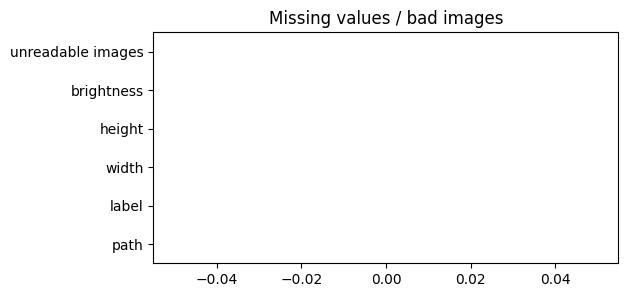

In [13]:
# missing value analysis
print(df.isnull().sum())
print("Unreadable images:", n_unreadable)

missing = df.isnull().sum()
missing["unreadable images"] = n_unreadable
plt.figure(figsize=(6, 3))
missing.plot(kind="barh")
plt.title("Missing values / bad images")
plt.savefig("screenshots/missing_value_analysis.png", bbox_inches="tight")
plt.show()

label
musti         400
pataka        400
simhamukha    400
trisula       400
sikhara       400
Name: count, dtype: int64


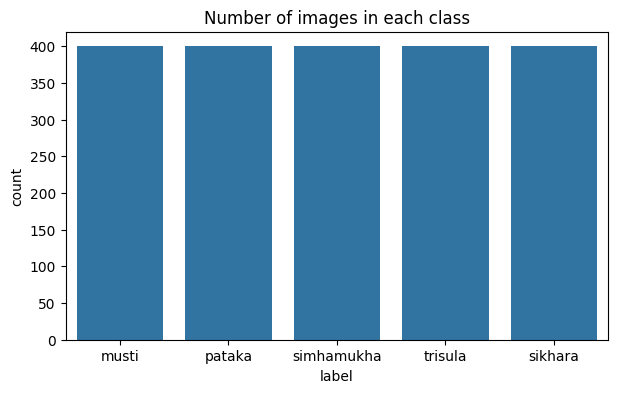

Biggest class / smallest class = 1.0


In [14]:
# class distribution
counts = df["label"].value_counts()
print(counts)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="label")
plt.title("Number of images in each class")
plt.savefig("screenshots/eda_class_distribution.png", bbox_inches="tight")
plt.show()

print("Biggest class / smallest class =", round(counts.max() / counts.min(), 2))

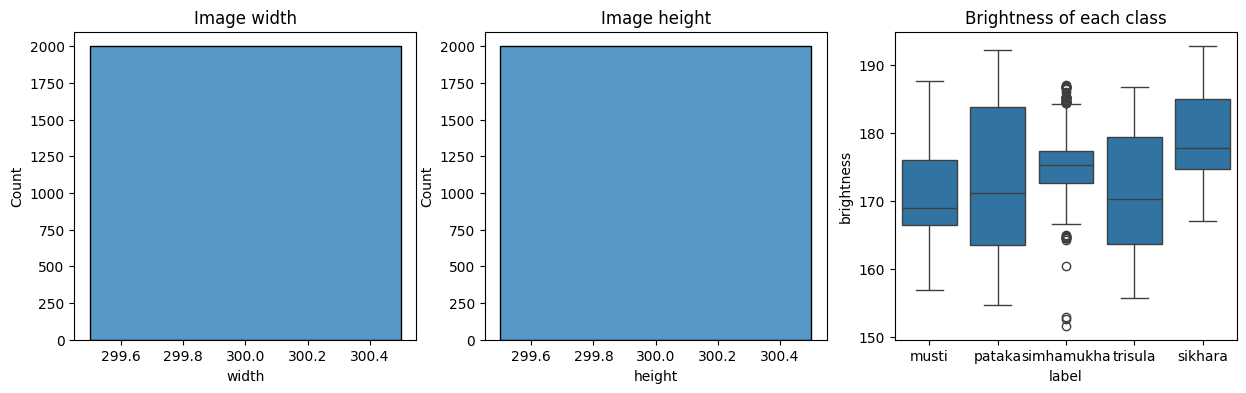

,width,height,brightness
count,2000.0,2000.0,2000.000000
mean,300.0,300.0,173.966247
std,0.0,0.0,8.294919
min,300.0,300.0,151.591011
25%,300.0,300.0,168.343603
50%,300.0,300.0,174.424094
75%,300.0,300.0,179.361858
max,300.0,300.0,192.846956


In [15]:
# image characteristics
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["width"], ax=axes[0])
axes[0].set_title("Image width")
sns.histplot(df["height"], ax=axes[1])
axes[1].set_title("Image height")
sns.boxplot(data=df, x="label", y="brightness", ax=axes[2])
axes[2].set_title("Brightness of each class")
plt.savefig("screenshots/eda_image_characteristics.png", bbox_inches="tight")
plt.show()

df[["width", "height", "brightness"]].describe()

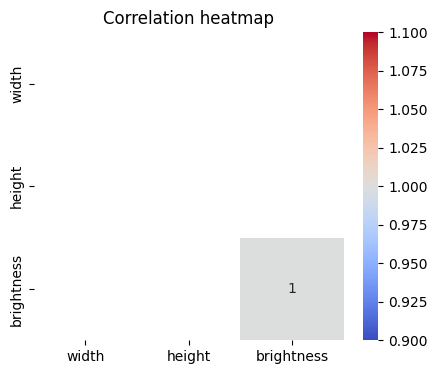

In [16]:
# correlation heatmap of the image features
plt.figure(figsize=(5, 4))
sns.heatmap(df[["width", "height", "brightness"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation heatmap")
plt.savefig("screenshots/correlation_heatmap.png", bbox_inches="tight")
plt.show()

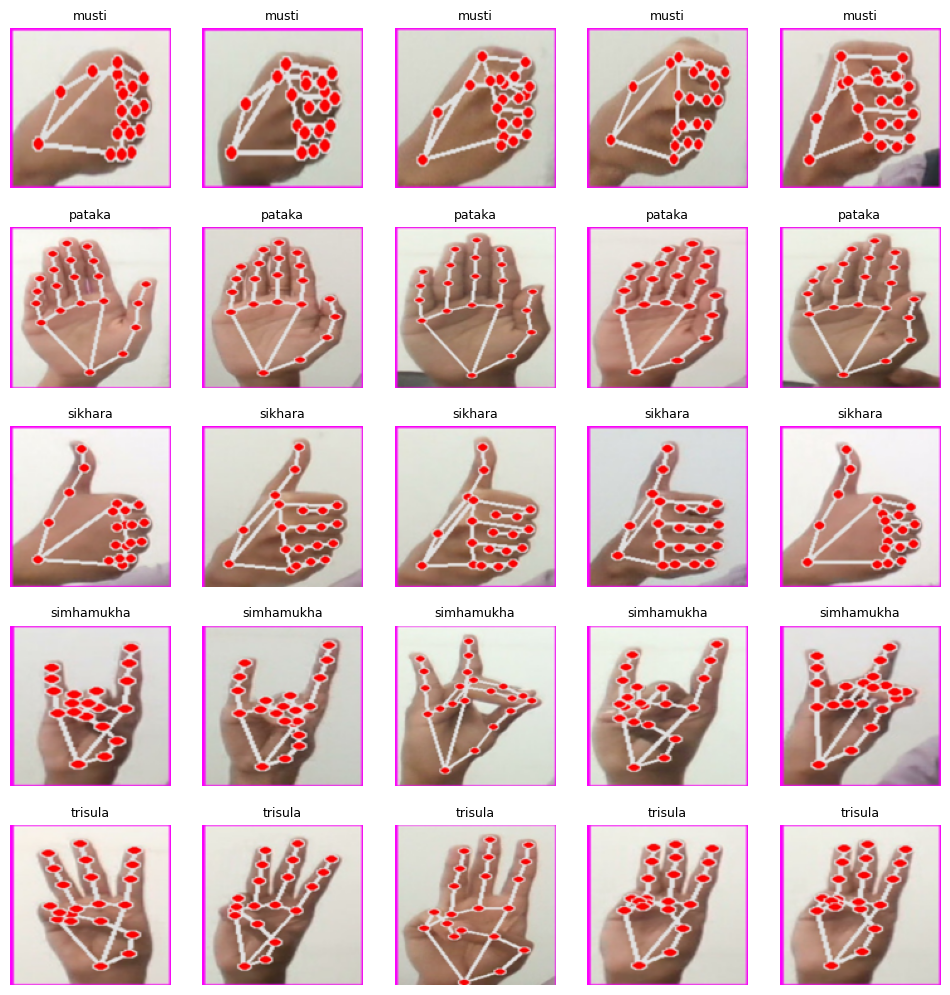

In [17]:
# dataset preview: 5 images from every class
class_list = sorted(df["label"].unique())
plt.figure(figsize=(12, 2.5 * len(class_list)))
n = 1
for c in class_list:
    sample = df[df["label"] == c].index[:5]
    for idx in sample:
        plt.subplot(len(class_list), 5, n)
        plt.imshow(X[idx])
        plt.title(c, fontsize=9)
        plt.axis("off")
        n += 1
plt.savefig("screenshots/dataset_preview.png", bbox_inches="tight")
plt.show()

### Train / validation / test split
I use 70% for training, 15% for validation and 15% for testing.

In [18]:
# convert the class names to numbers
encoder = LabelEncoder()
y = encoder.fit_transform(df["label"])
class_names = list(encoder.classes_)
print(class_names)

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# save the encoder, the app needs it
joblib.dump(encoder, "models/label_encoder.joblib")

['musti', 'pataka', 'sikhara', 'simhamukha', 'trisula']
Train: (1400, 128, 128, 3)
Validation: (300, 128, 128, 3)
Test: (300, 128, 128, 3)


['models/label_encoder.joblib']

### Analytical Questions (Task 1)

**1. Is the dataset balanced? How might imbalance affect learning?**

The class counts and the bar chart above show this. I divided the biggest class by the smallest class. If this number is close to 1 the dataset is balanced, if it is much bigger than 1 the dataset is imbalanced.

If a dataset is imbalanced, the model sees the big class more often, so it learns it better and predicts it too often. The small classes get low recall. Accuracy can also look high even when the small classes are mostly wrong. So with an imbalanced dataset I should use stratified splitting also look at precision/recall/F1 for each class not only accuracy, and can use class weights or more augmentation for the small classes.

**2. What image characteristics could make mudra recognition difficult?**

- Many mudras look almost the same. Only the position of the thumb is different.
- The same mudra looks different for different people based on the hand size, skin colour, left or right hand, angle of the wrist.
- Fingers can hide behind other fingers, so the important part is not visible.
- Background, shadows and lighting are different in different images.
- Images have different sizes, so resizing can stretch the hand and blur thin fingers.
- Small dataset, so the model may learn the background instead of the hand shape.

**3. Would increasing image resolution always improve performance? Justify.**

No. A higher resolution is useful only until the fingers are clearly visible. After that it only gives more noise and a lot more computation, and the bigger model can overfit a small dataset more easily.  A very low resolution is also bad because the fingers get merged. So I chose 128x128 as a balance between detail and speed.

# Task 2: Preprocessing and Augmentation


In [20]:
data_augmentation = keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2, value_range=(0, 1)),
    layers.RandomContrast(0.2),
])

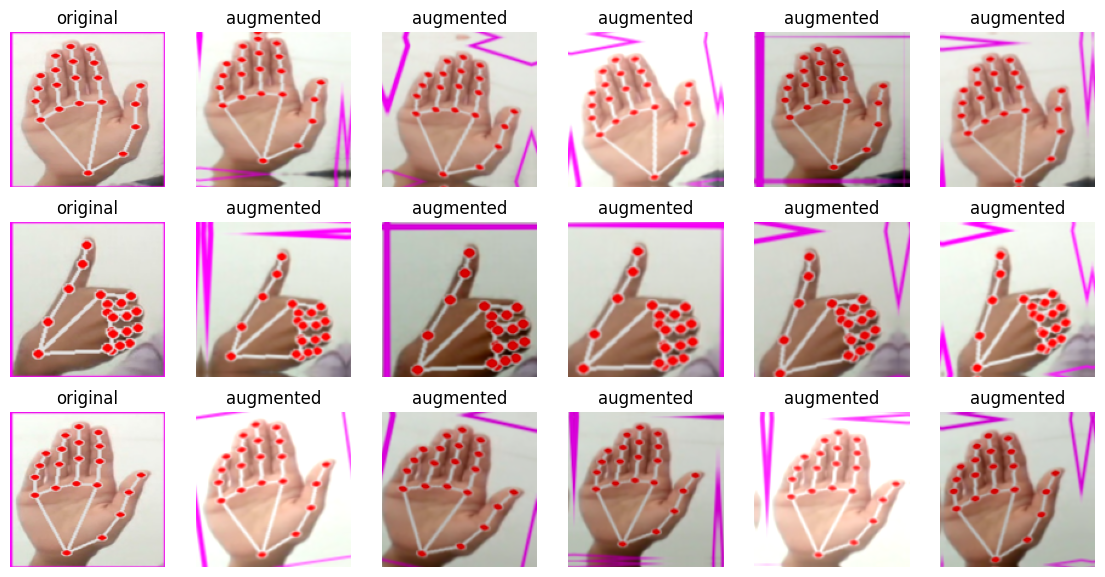

In [21]:
plt.figure(figsize=(14, 7))
for row in range(3):
    img = X_train[row]
    plt.subplot(3, 6, row * 6 + 1)
    plt.imshow(img)
    plt.title("original")
    plt.axis("off")
    for k in range(5):
        aug = data_augmentation(np.expand_dims(img, 0), training=True)[0].numpy()
        plt.subplot(3, 6, row * 6 + k + 2)
        plt.imshow(np.clip(aug, 0, 1))
        plt.title("augmented")
        plt.axis("off")
plt.savefig("screenshots/augmentation_samples.png", bbox_inches="tight")
plt.show()

### Analytical Questions (Task 2)

**1. Which augmentation techniques preserve the semantic meaning of hand gestures?**

Small changes that do not change the finger positions: small rotation,hand not exactly in the center, and brightness / contrast changes. Light blur or noise is also fine. The meaning of the mudra depends on how the fingers are arranged and these changes keep that same.

**2. Which augmentations could negatively impact classification accuracy, and why?**

- Big rotations and vertical flip: the direction of the palm matters
- Big zoom or crop: the fingertips can get cut out and the label is no longer visible.
- Shear or perspective warp: it changes the finger angles, which is what separates the mudras.
- Strong colour change: gives unnatural skin colour and does not help.
- Horizontal flip: it turns a right hand into a left hand. This can be fine for mudras that are made with either hand, but it is risky, so I did not use it.

# Task 3: CNN Development


In [22]:
def build_cnn(learning_rate, dropout_rate):
    model = keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        data_augmentation,

        layers.Conv2D(32, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation="relu", padding="same"),
        layers.MaxPooling2D(),

        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(len(class_names), activation="softmax"),
    ])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy"])
    return model

build_cnn(0.001, 0.3).summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,405 (431.27 KB)

 Trainable params: 110,405 (431.27 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
learning_rates = [0.001, 0.0003]
dropout_rates = [0.3, 0.5]

results = []
for lr in learning_rates:
    for dr in dropout_rates:
        model = build_cnn(lr, dr)
        h = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                      epochs=EPOCHS_TUNE, batch_size=BATCH_SIZE, verbose=0)
        best_val_acc = max(h.history["val_accuracy"])
        results.append([lr, dr, best_val_acc])
        print("learning rate", lr, "| dropout", dr, "| best val accuracy", round(best_val_acc, 3))

results_df = pd.DataFrame(results, columns=["learning_rate", "dropout", "val_accuracy"])
results_df = results_df.sort_values("val_accuracy", ascending=False).reset_index(drop=True)
results_df

learning rate 0.001 | dropout 0.3 | best val accuracy 0.47
learning rate 0.001 | dropout 0.5 | best val accuracy 0.71
learning rate 0.0003 | dropout 0.3 | best val accuracy 0.553
learning rate 0.0003 | dropout 0.5 | best val accuracy 0.653


,learning_rate,dropout,val_accuracy
0,0.0010,0.5,0.710000
1,0.0003,0.5,0.653333
2,0.0003,0.3,0.553333
3,0.0010,0.3,0.470000


Best learning rate: 0.001
Best dropout: 0.5


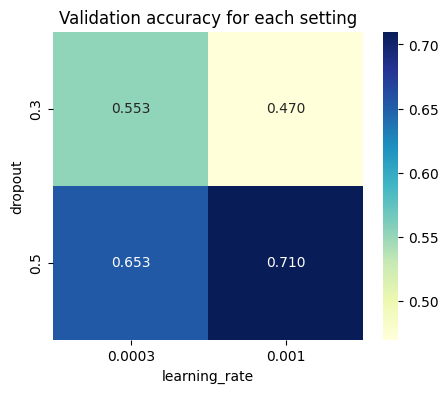

In [24]:
best_lr = results_df["learning_rate"][0]
best_dropout = results_df["dropout"][0]
print("Best learning rate:", best_lr)
print("Best dropout:", best_dropout)

plt.figure(figsize=(5, 4))
sns.heatmap(results_df.pivot(index="dropout", columns="learning_rate", values="val_accuracy"),
            annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Validation accuracy for each setting")
plt.savefig("screenshots/hyperparameter_tuning.png", bbox_inches="tight")
plt.show()

### Train the final CNN


In [25]:
cnn = build_cnn(best_lr, best_dropout)

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

start = time.time()
history = cnn.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=EPOCHS_FINAL, batch_size=BATCH_SIZE, callbacks=[early_stop])
cnn_train_time = time.time() - start
print("Training time (seconds):", round(cnn_train_time))

cnn.save("models/mudra_cnn.keras")

Epoch 1/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.1950 - loss: 1.6117 - val_accuracy: 0.2000 - val_loss: 1.5950
Epoch 2/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.2871 - loss: 1.5505 - val_accuracy: 0.5433 - val_loss: 1.3823
Epoch 3/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.3557 - loss: 1.4335 - val_accuracy: 0.4233 - val_loss: 1.2599
Epoch 4/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.4493 - loss: 1.2567 - val_accuracy: 0.6400 - val_loss: 0.9517
Epoch 5/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.5229 - loss: 1.0546 - val_accuracy: 0.6700 - val_loss: 0.8051
Epoch 6/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.6021 - loss: 0.8839 - val_accuracy: 0.5967 - val_loss: 0.8211
Epoch 7/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 69s 2s/step - accuracy: 0.6579 - loss: 0.7874 - val_accuracy: 0.6067 - val_loss: 0.8005
Epoch 8/25
44/44 ━━━━━━━━━━━━━━━━━━━━ 76s 1s/step - accuracy: 0.7007 - loss: 0.7045 - val_accuracy: 0.6267 - val_loss:

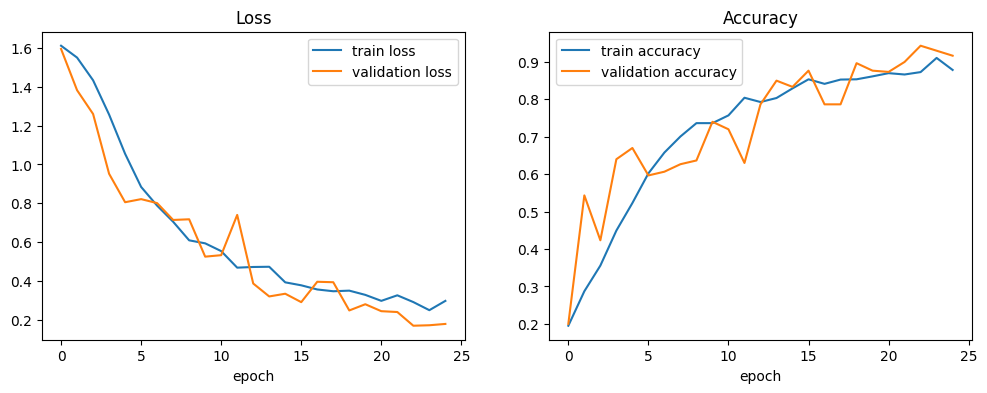

Final train accuracy: 0.879
Final validation accuracy: 0.917
Difference: -0.038


In [26]:
# training and validation curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.xlabel("epoch")
plt.title("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["accuracy"], label="train accuracy")
plt.plot(history.history["val_accuracy"], label="validation accuracy")
plt.xlabel("epoch")
plt.title("Accuracy")
plt.legend()

plt.savefig("screenshots/training_validation_curves.png", bbox_inches="tight")
plt.show()

train_acc = history.history["accuracy"][-1]
val_acc = history.history["val_accuracy"][-1]
print("Final train accuracy:", round(train_acc, 3))
print("Final validation accuracy:", round(val_acc, 3))
print("Difference:", round(train_acc - val_acc, 3))

### Analytical Questions (Task 3)

**1. Explain the effect of your hyperparameter choices.**

- **Learning rate**: this is the step size of the optimizer. If it is too big the loss jumps around and the model can miss the best point, if it is too small the training is slow and needs more epochs. The heat map above shows which value gave the best validation accuracy.
- **Dropout rate**: dropout randomly switches off some neurons while training, so the model cannot depend on only a few neurons. A higher dropout reduces overfitting, but if it is too high the model learns slowly and can underfit. The table above shows which value worked best.

The best values are printed above (`Best learning rate`, `Best dropout`). I also used early stopping, data augmentation and global average pooling to reduce overfitting.

**2. Did your model show underfitting or overfitting? Support your answer using the learning curves.**

Look at the curves and at the difference between train and validation accuracy printed above:

- **Underfitting**: both train and validation accuracy are low and the loss stays high.
- **Overfitting**: train accuracy keeps going up and the loss keeps going down, but the validation loss starts to go up and validation accuracy stays behind. The gap between train and validation is big (more than about 10%).
- **Good fit**: both curves improve together and stay close.


# Task 4: Model Evaluation and Failure Analysis
All the results below use the **test set**, which the model has never seen.

In [27]:
y_prob = cnn.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)
confidence = np.max(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))
print()
print(classification_report(y_test, y_pred, target_names=class_names, zero_division=0))

10/10 ━━━━━━━━━━━━━━━━━━━━ 7s 706ms/step
Accuracy : 0.9567
Precision: 0.9604
Recall   : 0.9567
F1-score : 0.9558

              precision    recall  f1-score   support

       musti       1.00      1.00      1.00        60
      pataka       0.98      1.00      0.99        60
     sikhara       0.98      1.00      0.99        60
  simhamukha       0.98      0.80      0.88        60
     trisula       0.86      0.98      0.91        60

    accuracy                           0.96       300
   macro avg       0.96      0.96      0.96       300
weighted avg       0.96      0.96      0.96       300



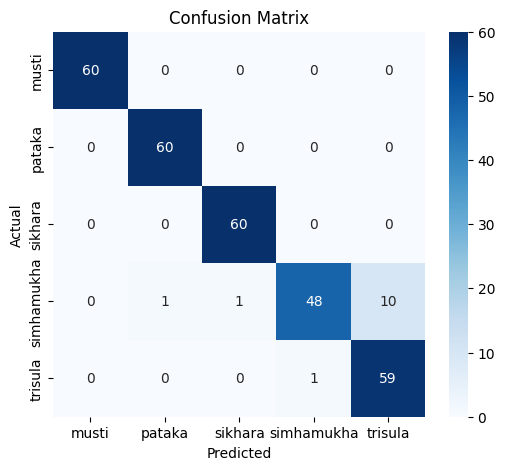

In [28]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.savefig("screenshots/confusion_matrix.png", bbox_inches="tight")
plt.show()

Number of wrong predictions: 13


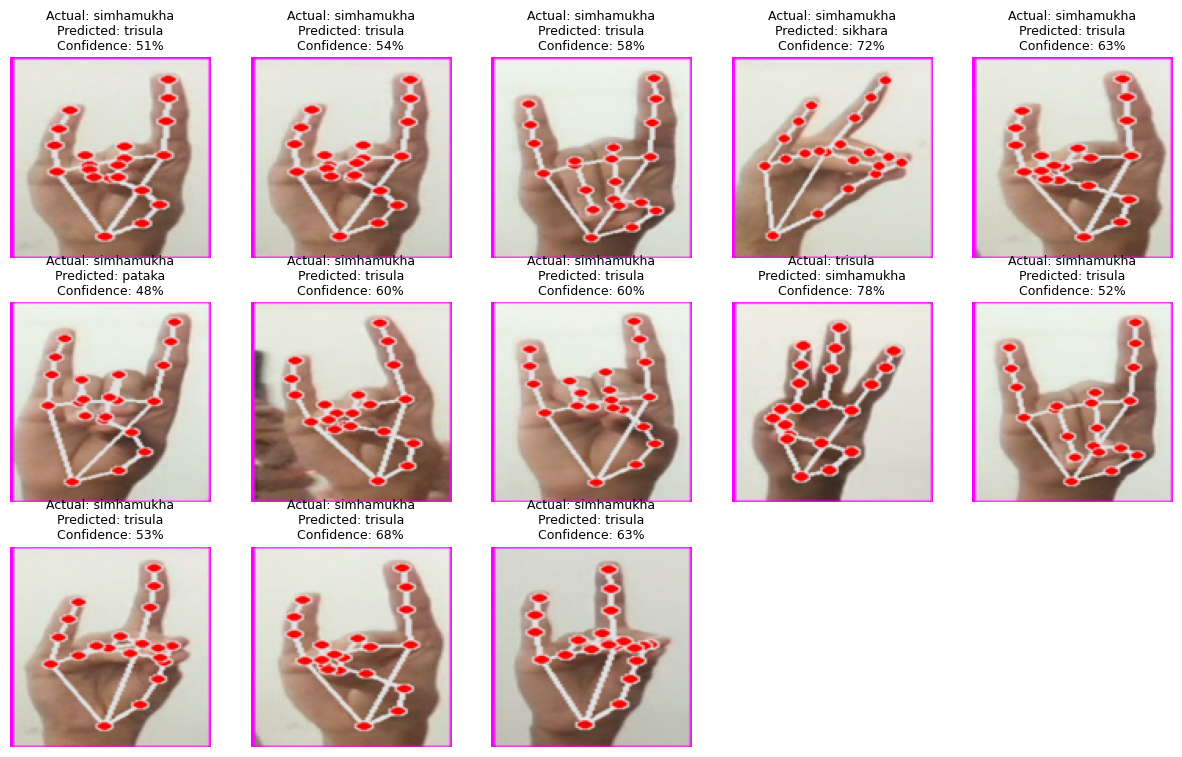

In [29]:
# misclassified images
wrong = np.where(y_pred != y_test)[0]
print("Number of wrong predictions:", len(wrong))

plt.figure(figsize=(15, 9))
for i in range(min(15, len(wrong))):
    idx = wrong[i]
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[idx])
    plt.title("Actual: " + class_names[y_test[idx]] + "\nPredicted: " + class_names[y_pred[idx]]
              + "\nConfidence: " + str(round(confidence[idx] * 100)) + "%", fontsize=9)
    plt.axis("off")
plt.savefig("screenshots/misclassified_images.png", bbox_inches="tight")
plt.show()

In [30]:
# confidence score of every incorrect prediction
errors = pd.DataFrame({
    "actual": [class_names[i] for i in y_test[wrong]],
    "predicted": [class_names[i] for i in y_pred[wrong]],
    "confidence": confidence[wrong].round(3),
})
errors = errors.sort_values("confidence", ascending=False).reset_index(drop=True)
errors

,actual,predicted,confidence
0,trisula,simhamukha,0.777
1,simhamukha,sikhara,0.724
2,simhamukha,trisula,0.676
3,simhamukha,trisula,0.634
4,simhamukha,trisula,0.628
5,simhamukha,trisula,0.599
6,simhamukha,trisula,0.598
7,simhamukha,trisula,0.582
8,simhamukha,trisula,0.539
9,simhamukha,trisula,0.525


In [31]:
# which pair of mudras is confused the most?
best_pair = None
best_count = 0
for i in range(len(class_names)):
    for j in range(i + 1, len(class_names)):
        total = cm[i][j] + cm[j][i]       # i predicted as j, and j predicted as i
        print(class_names[i], "and", class_names[j], ":", total, "mistakes")
        if total > best_count:
            best_count = total
            best_pair = (class_names[i], class_names[j])
print()
print("Most confused pair:", best_pair, "with", best_count, "mistakes")

musti and pataka : 0 mistakes
musti and sikhara : 0 mistakes
musti and simhamukha : 0 mistakes
musti and trisula : 0 mistakes
pataka and sikhara : 0 mistakes
pataka and simhamukha : 1 mistakes
pataka and trisula : 0 mistakes
sikhara and simhamukha : 1 mistakes
sikhara and trisula : 0 mistakes
simhamukha and trisula : 11 mistakes

Most confused pair: ('simhamukha', 'trisula') with 11 mistakes


Average confidence of correct predictions: 0.902
Average confidence of wrong predictions  : 0.599
Wrong predictions with confidence above 80%: 0 out of 13


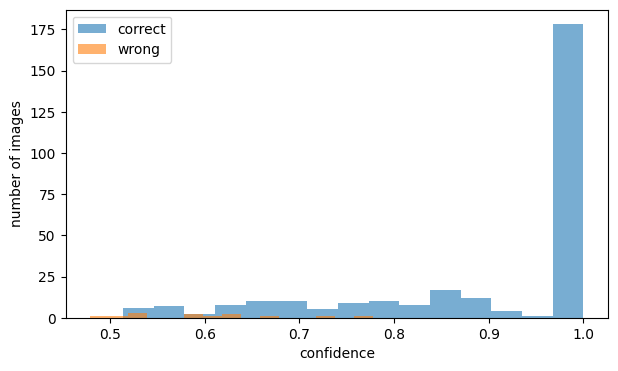

In [32]:
# confidence of correct vs wrong predictions
right = np.where(y_pred == y_test)[0]
print("Average confidence of correct predictions:", round(confidence[right].mean(), 3))
if len(wrong) > 0:
    print("Average confidence of wrong predictions  :", round(confidence[wrong].mean(), 3))
    print("Wrong predictions with confidence above 80%:", (confidence[wrong] > 0.8).sum(), "out of", len(wrong))

plt.figure(figsize=(7, 4))
plt.hist(confidence[right], bins=15, alpha=0.6, label="correct")
plt.hist(confidence[wrong], bins=15, alpha=0.6, label="wrong")
plt.xlabel("confidence")
plt.ylabel("number of images")
plt.legend()
plt.savefig("screenshots/confidence_distribution.png", bbox_inches="tight")
plt.show()

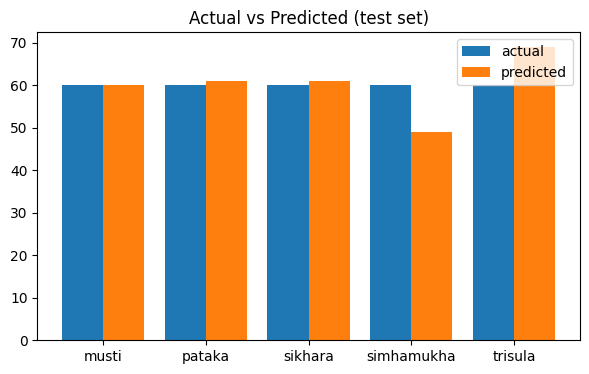

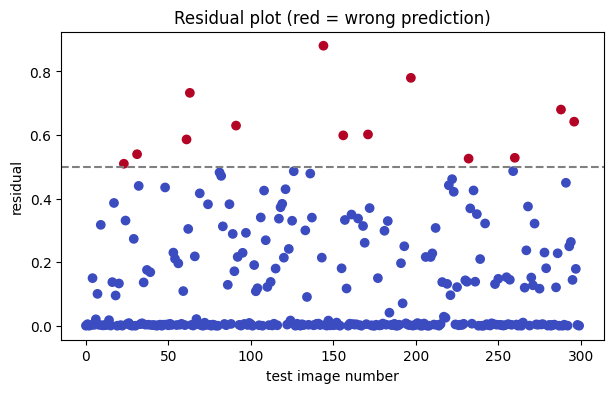

In [33]:
# actual vs predicted plot (number of images of each class)
actual_counts = np.bincount(y_test, minlength=len(class_names))
pred_counts = np.bincount(y_pred, minlength=len(class_names))
x = np.arange(len(class_names))

plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, actual_counts, width=0.4, label="actual")
plt.bar(x + 0.2, pred_counts, width=0.4, label="predicted")
plt.xticks(x, class_names)
plt.legend()
plt.title("Actual vs Predicted (test set)")
plt.savefig("screenshots/actual_vs_predicted.png", bbox_inches="tight")
plt.show()

# residual plot: residual = 1 - probability given to the true class
# (0 means the model was sure and correct, close to 1 means very wrong)
residual = 1 - y_prob[np.arange(len(y_test)), y_test]
plt.figure(figsize=(7, 4))
plt.scatter(range(len(residual)), residual, c=(y_pred != y_test), cmap="coolwarm")
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("test image number")
plt.ylabel("residual")
plt.title("Residual plot (red = wrong prediction)")
plt.savefig("screenshots/residual_plot.png", bbox_inches="tight")
plt.show()

### Analytical Questions (Task 4)

**1. Which mudra pair is most frequently confused? Explain the visual similarity.**

The most confused pair is printed above ("Most confused pair"). Mudras are confused when the hand shape is almost the same and only one finger or the thumb is different. The misclassified images above show this.

**2. Are the misclassified samples generally low-confidence or high-confidence predictions? What does this indicate?**

Check the average confidence of the wrong predictions and the histogram above.

- If most wrong predictions have **low confidence**, the model knows when it is not sure. This is good, because the app can show a warning for low confidence predictions.
- If many wrong predictions have **high confidence**, the model is over-confident. This means the two classes look very similar, or some labels may be wrong, and the confidence score alone cannot be trusted.

**3. Suggest one data-centric and one model-centric improvement.**

- Data-centric: collect more images of the confused mudras with different people, angles, lights and backgrounds, and remove wrongly labelled images.
- Model-centric: use transfer learning with a pretrained model  or fine tune it, which usually learns finer details better.

In [34]:
# save info for the Streamlit app
info = {
    "class_names": class_names,
    "img_size": IMG_SIZE,
    "total_images": int(len(df)),
    "class_counts": {k: int(v) for k, v in counts.items()},
    "train_size": int(len(X_train)),
    "val_size": int(len(X_val)),
    "test_size": int(len(X_test)),
    "learning_rate": float(best_lr),
    "dropout": float(best_dropout),
}

# Task 5: Streamlit Deployment

In [35]:
%%writefile app.py
import json
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import tensorflow as tf
from PIL import Image

st.set_page_config(page_title="Mudra Recognition")

# load the model, encoder and info saved by the notebook
@st.cache_resource
def load_files():
    model = tf.keras.models.load_model("models/mudra_model.keras")
    encoder = joblib.load("models/label_encoder.joblib")
    info = json.load(open("models/model_info.json"))
    return model, encoder, info

model, encoder, info = load_files()
IMG_SIZE = info["img_size"]
class_names = list(encoder.classes_)

page = st.sidebar.radio("Go to", ["Home", "Predict", "About"])

# ---------------- Home ----------------
if page == "Home":
    st.title("Bharatanatyam Mudra Recognition")
    st.write("This app recognizes 5 Bharatanatyam hand mudras from an image "
             "and tells how confident the model is.")
    st.subheader("How to use")
    st.write("1. Go to the Predict page")
    st.write("2. Upload a clear photo of your hand")
    st.write("3. See the predicted mudra, the confidence and the probability of every class")
    st.write("Mudras this model can recognize:")
    for name in class_names:
        st.write("- " + name.title())

# ---------------- Predict ----------------
elif page == "Predict":
    st.title("Predict the Mudra")
    uploaded = st.file_uploader("Upload an image", type=["jpg", "jpeg", "png"])

    if uploaded is not None:
        image = Image.open(uploaded).convert("RGB")
        st.image(image, caption="Uploaded image", width=300)

        # same preprocessing as in the notebook: resize and divide by 255
        img = image.resize((IMG_SIZE, IMG_SIZE))
        img = np.array(img, dtype="float32") / 255.0
        img = np.expand_dims(img, axis=0)

        probs = model.predict(img)[0]
        best = np.argmax(probs)
        confidence = probs[best] * 100

        st.subheader("Result")
        st.write("Predicted mudra: **" + class_names[best].title() + "**")
        st.write("Confidence: **" + str(round(confidence, 2)) + "%**")

        if confidence < 60:
            st.warning("The model is not very sure. Try a clearer photo with a plain background.")

        st.subheader("Probability of all classes")
        chart_data = pd.DataFrame({"Mudra": [c.title() for c in class_names], "Probability": probs})
        st.bar_chart(chart_data.set_index("Mudra"))
        st.table(chart_data)

# ---------------- About ----------------
else:
    st.title("About")
    st.subheader("Dataset")
    st.write("Total images:", info["total_images"])
    st.write("Train / Validation / Test:", info["train_size"], "/", info["val_size"], "/", info["test_size"])
    st.write("Images in each class:")
    st.bar_chart(pd.Series(info["class_counts"]))

    st.subheader("Model")
    st.write("Model used: " + info["model_name"])
    st.write("Test accuracy: " + str(round(info["test_accuracy"] * 100, 2)) + "%")
    st.write("Input size: " + str(IMG_SIZE) + " x " + str(IMG_SIZE) + " (RGB), pixel values divided by 255")
    st.write("Custom CNN settings: learning rate " + str(info["learning_rate"]) + ", dropout " + str(info["dropout"]))


Writing app.py


### Analytical Questions (Task 5)

**1. Why is displaying prediction confidence important for end users?**

The confidence tells the student how sure the model is. A prediction with 95% confidence can be trusted more, but a prediction with 40% confidence means the image is not clear or the hand shape is between two mudras. Without it the student may believe a wrong answer. It also helps to find bad inputs (blurry photo, not a hand), and the probabilities of the other classes show which mudra the hand is being confused with.

**2. What additional feature would make this application more useful for dance learners?**

A practice mode with live webcam: the student chooses a mudra to practice and the app says if the hand is correct, and also tells which finger is wrong. Other useful things: a reference photo and the meaning of each mudra, and a score history to track progress.### Analytical Questions (Task 5)


# Bonus: Transfer Learning (MobileNetV2)
MobileNetV2 is already trained on ImageNet, so it already knows edges and shapes. I keep it frozen and train only a new output layer first, then unfreeze the last layers and train a little more with a very small learning rate (fine tuning).

In [36]:
base_model = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                            include_top=False, weights="imagenet")
base_model.trainable = False

tl_model = keras.Sequential([
    keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    data_augmentation,
    layers.Rescaling(2.0, offset=-1.0),      # MobileNetV2 wants values between -1 and 1
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax"),
])

start = time.time()

# step 1: train only the new output layer
tl_model.compile(optimizer=keras.optimizers.Adam(0.001),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = tl_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=EPOCHS_TL, batch_size=BATCH_SIZE)

# step 2: unfreeze the last 30 layers of MobileNetV2 and fine tune
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
tl_model.compile(optimizer=keras.optimizers.Adam(0.00001),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = tl_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                  epochs=EPOCHS_FT, batch_size=BATCH_SIZE)

tl_train_time = time.time() - start
print("Training time (seconds):", round(tl_train_time))
tl_model.save("models/mudra_mobilenetv2.keras")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 45s 818ms/step - accuracy: 0.6779 - loss: 0.9030 - val_accuracy: 0.9733 - val_loss: 0.1274
Epoch 2/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 30s 691ms/step - accuracy: 0.9514 - loss: 0.1921 - val_accuracy: 0.9967 - val_loss: 0.0456
Epoch 3/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 42s 708ms/step - accuracy: 0.9800 - loss: 0.1044 - val_accuracy: 1.0000 - val_loss: 0.0201
Epoch 4/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 41s 700ms/step - accuracy: 0.9786 - loss: 0.0872 - val_accuracy: 1.0000 - val_loss: 0.0124
Epoch 5/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 32s 736ms/step - accuracy: 0.9864 - loss: 0.0613 - val_accuracy: 1.0000 - val_loss: 0.0102
Epoch 6/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 43s 775ms/step - accuracy: 0.9907 - loss: 0.0468 - val_accuracy: 1.0000 - val_loss: 0.0068
Epoch 7/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 36s 666ms/step - accuracy: 0.9907 - loss: 0.0403 - val_accuracy: 1.0000 - val_loss: 0.0052
Epoch 8/8
44/44 ━━━━━━━━━━━━━━━━━━━━ 43s 706ms/step - a

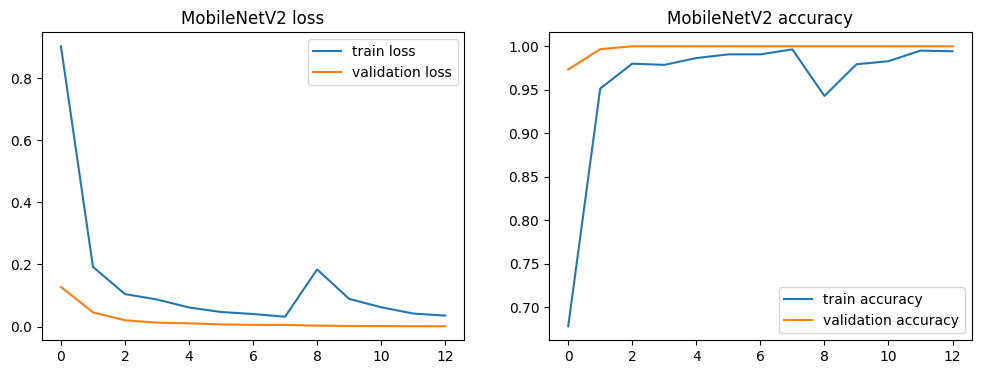

In [37]:
# training curves for MobileNetV2
tl_loss = h1.history["loss"] + h2.history["loss"]
tl_val_loss = h1.history["val_loss"] + h2.history["val_loss"]
tl_acc = h1.history["accuracy"] + h2.history["accuracy"]
tl_val_acc = h1.history["val_accuracy"] + h2.history["val_accuracy"]

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(tl_loss, label="train loss")
plt.plot(tl_val_loss, label="validation loss")
plt.title("MobileNetV2 loss")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(tl_acc, label="train accuracy")
plt.plot(tl_val_acc, label="validation accuracy")
plt.title("MobileNetV2 accuracy")
plt.legend()
plt.savefig("screenshots/training_validation_curves_mobilenetv2.png", bbox_inches="tight")
plt.show()

In [38]:
# compare both models: accuracy, size, training time, inference speed
def inference_time(model):
    # average time to predict one image (in milliseconds)
    model.predict(X_test[:1], verbose=0)         # warm up
    start = time.time()
    for i in range(20):
        model.predict(X_test[i:i + 1], verbose=0)
    return (time.time() - start) / 20 * 1000

def file_size(path):
    return os.path.getsize(path) / (1024 * 1024)   # MB

cnn_acc = accuracy_score(y_test, np.argmax(cnn.predict(X_test), axis=1))
tl_acc_test = accuracy_score(y_test, np.argmax(tl_model.predict(X_test), axis=1))

comparison = pd.DataFrame({
    "Model": ["Custom CNN", "MobileNetV2"],
    "Test accuracy": [cnn_acc, tl_acc_test],
    "Model size (MB)": [file_size("models/mudra_cnn.keras"), file_size("models/mudra_mobilenetv2.keras")],
    "Training time (s)": [cnn_train_time, tl_train_time],
    "Inference time (ms/image)": [inference_time(cnn), inference_time(tl_model)],
})
comparison.round(3)

10/10 ━━━━━━━━━━━━━━━━━━━━ 4s 351ms/step
10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 504ms/step


,Model,Test accuracy,Model size (MB),Training time (s),Inference time (ms/image)
0,Custom CNN,0.957,1.323,1721.862,152.565
1,MobileNetV2,1.000,20.929,540.066,106.200


In [39]:
# the better model (higher test accuracy) is used in the app
if tl_acc_test > cnn_acc:
    best_model_name = "MobileNetV2"
    shutil.copy("models/mudra_mobilenetv2.keras", "models/mudra_model.keras")
else:
    best_model_name = "Custom CNN"
    shutil.copy("models/mudra_cnn.keras", "models/mudra_model.keras")
print("Model used in the app:", best_model_name)

info["model_name"] = best_model_name
info["test_accuracy"] = float(max(cnn_acc, tl_acc_test))
json.dump(info, open("models/model_info.json", "w"), indent=2)

Model used in the app: MobileNetV2


### Which model should be deployed?

Look at the comparison table above:
- **Accuracy**: the more accurate model gives better feedback to the students, so this is the most important point.
- **Model size**: a small model is easier to host and could run on a phone.
- **Training time**: the custom CNN is trained from scratch, MobileNetV2 only trains a small part so it can be retrained faster when new images are added.
- **Inference speed**: lower time means faster feedback.

My recommendation is the model that has the higher test accuracy (it is saved as `models/mudra_model.keras` and printed above). If the accuracies are almost the same, I would pick the smaller and faster model. Usually MobileNetV2 is better here because it is pretrained and small, so it works well even with a small dataset.

# **Requirements**

In [40]:
%%writefile requirements.txt
tensorflow
streamlit
numpy
pandas
pillow
scikit-learn
matplotlib
seaborn
joblib
jupyter

Writing requirements.txt


# **README**

In [41]:
%%writefile README.md
# Bharatanatyam Mudra Recognition

A CNN that recognizes 5 Bharatanatyam hand mudras from an image. A Streamlit app shows the predicted mudra, the confidence and the probability of every class.

## Files
- mudra_classification.ipynb : full notebook (analysis, training, evaluation)
- app.py : Streamlit app
- models/ : trained model (.keras), label encoder and model info
- screenshots/ : plots and app screenshots
- requirements.txt : libraries needed

## How to run
1. Install libraries:
   pip install -r requirements.txt
2. Open the notebook and run all cells (needs mudra.zip, not included here).
3. Start the app:
   streamlit run app.py

Writing README.md


In [42]:
!zip -r project_files.zip models screenshots app.py requirements.txt README.md
from google.colab import files
files.download("project_files.zip")

  adding: models/ (stored 0%)
  adding: models/mudra_model.keras (deflated 10%)
  adding: models/mudra_mobilenetv2.keras (deflated 10%)
  adding: models/label_encoder.joblib (deflated 35%)
  adding: models/model_info.json (deflated 51%)
  adding: models/mudra_cnn.keras (deflated 10%)
  adding: screenshots/ (stored 0%)
  adding: screenshots/eda_class_distribution.png (deflated 17%)
  adding: screenshots/hyperparameter_tuning.png (deflated 9%)
  adding: screenshots/dataset_preview.png (deflated 0%)
  adding: screenshots/augmentation_samples.png (deflated 0%)
  adding: screenshots/eda_image_characteristics.png (deflated 16%)
  adding: screenshots/residual_plot.png (deflated 3%)
  adding: screenshots/correlation_heatmap.png (deflated 12%)
  adding: screenshots/actual_vs_predicted.png (deflated 15%)
  adding: screenshots/training_validation_curves.png (deflated 4%)
  adding: screenshots/missing_value_analysis.png (deflated 15%)
  adding: screenshots/confusion_matrix.png (deflated 10%)
  add

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>